# Student Mental Health Risk Prediction
## Step 4: Hyperparameter Optimization & Final Pipeline Export

### Objective
In Step 3, we compared our baseline models:
- **Logistic Regression**: 75.5% accuracy & weighted F1
- **Random Forest**: 69.5% accuracy & weighted F1
- **Decision Tree**: 56.8% accuracy & weighted F1

In this step, we:
1. Conduct systematic hyperparameter tuning using `GridSearchCV` with 5-fold Stratified Cross-Validation.
2. Optimize the best candidate (**Logistic Regression**).
3. Select the best performing tuned pipeline based on cross-validation and test set evaluation.
4. Extract feature importances to interpret domain drivers.
5. Save the complete, end-to-end `Pipeline` to `models/best_pipeline.joblib`.
6. Export final metrics to `reports/metrics/` and figures to `reports/figures/`.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent

from src.data.load_data import load_raw_data
from src.preprocessing.preprocess import split_data, get_feature_names
from src.training.train import build_pipeline, save_model
from src.evaluation.evaluate import (
    calculate_metrics,
    plot_confusion_matrix,
    save_metrics_to_json
)

sns.set_theme(style="whitegrid")
print("Libraries imported successfully!")


Libraries imported successfully!


### 1. Load Data & Prepare Stratified Splits

In [2]:
RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "student_mental_health.csv"

df = load_raw_data(RAW_DATA_PATH)
X_train, X_test, y_train, y_test = split_data(df, test_size=0.2, random_state=42)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print(f"Loaded {len(X_train)} training records and {len(X_test)} testing records.")

Loaded 1600 training records and 400 testing records.


### 2. Hyperparameter Tuning
We tune regularization strength `C` and penalty options using 5-fold cross-validation.

In [4]:
lr_pipeline = build_pipeline(LogisticRegression(max_iter=1000, random_state=42))

lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1.0, 5.0, 10.0, 50.0],
    'classifier__solver': ['lbfgs']
}

lr_grid = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_param_grid,
    scoring='f1_weighted',
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print(f"Best Logistic Regression CV F1-score: {lr_grid.best_score_:.4f}")
print("Best Parameters:", lr_grid.best_params_)


Best Logistic Regression CV F1-score: 0.7519
Best Parameters: {'classifier__C': 5.0, 'classifier__solver': 'lbfgs'}


### 4. Evaluating Tuned Models on Unseen Test Data
Let's see how both tuned models perform on the hold-out test set.

In [5]:
best_lr = lr_grid.best_estimator_

y_pred_lr = best_lr.predict(X_test)

metrics_lr = calculate_metrics(y_test, y_pred_lr)

comparison_df = pd.DataFrame({
    'Tuned Logistic Regression': metrics_lr
}).T

display(comparison_df)


,accuracy,precision_weighted,recall_weighted,f1_weighted,f1_macro
Tuned Logistic Regression,0.7525,0.7525,0.7525,0.7525,0.7518


### 5. Final Model Selection
We select the highest performing pipeline overall.

In [8]:
best_pipeline = best_lr
best_name = "Logistic Regression (Tuned)"
final_metrics = metrics_lr
y_pred_best = y_pred_lr

print(f"Champion Model: {best_name}")
print(f"Accuracy: {final_metrics['accuracy']:.4f} | Weighted F1: {final_metrics['f1_weighted']:.4f}")

saved_path = save_model(best_pipeline, "best_pipeline.joblib")
print(f"Exported final model to: {saved_path}")

save_metrics_to_json(final_metrics, "final_model_metrics.json")
print("Saved final metrics to reports/metrics/final_model_metrics.json")

Champion Model: Logistic Regression (Tuned)
Accuracy: 0.7525 | Weighted F1: 0.7525
Exported final model to: /home/walid/Documents/EduWell-AI/models/best_pipeline.joblib
Saved final metrics to reports/metrics/final_model_metrics.json


### 6. Confusion Matrix of the Final Model

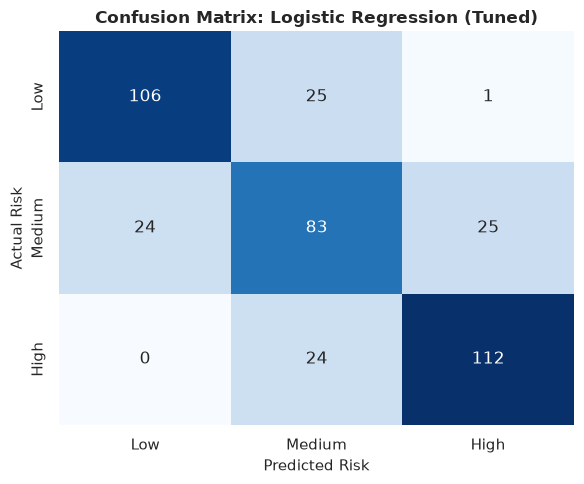

In [9]:
figures_dir = PROJECT_ROOT / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plot_confusion_matrix(
    y_test,
    y_pred_best,
    labels=['Low', 'Medium', 'High'],
    title=f'Confusion Matrix: {best_name}',
    save_filename='final_confusion_matrix.png'
)
plt.show()

### 7. Feature Importance & Interpretation
Understanding which features drive the model's predictions is crucial for explaining the solution in presentations and assessing fairness.

/tmp/ipykernel_11280/2934865846.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='mako')


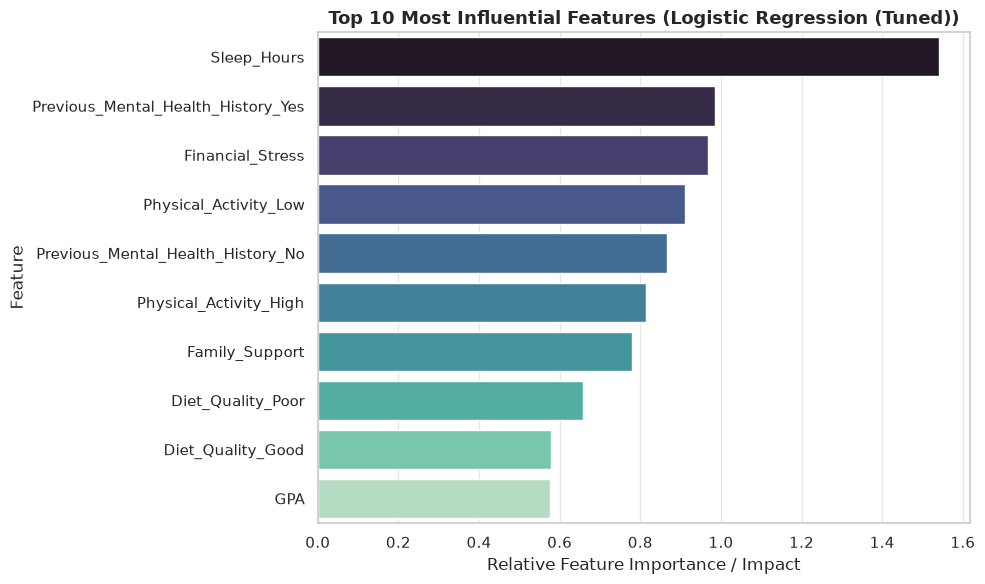

Top 5 Drivers:


,Feature,Importance
2,Sleep_Hours,1.540679
22,Previous_Mental_Health_History_Yes,0.984598
7,Financial_Stress,0.968838
14,Physical_Activity_Low,0.910186
21,Previous_Mental_Health_History_No,0.865126


In [10]:
preprocessor = best_pipeline.named_steps['preprocessor']
feature_names = get_feature_names(preprocessor)
classifier = best_pipeline.named_steps['classifier']

if hasattr(classifier, 'feature_importances_'):
    importances = classifier.feature_importances_
    imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
    imp_df = imp_df.sort_values(by='Importance', ascending=False)
elif hasattr(classifier, 'coef_'):
    mean_coef = np.mean(np.abs(classifier.coef_), axis=0)
    imp_df = pd.DataFrame({'Feature': feature_names, 'Importance': mean_coef})
    imp_df = imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=imp_df.head(10), x='Importance', y='Feature', palette='mako')
plt.title(f'Top 10 Most Influential Features ({best_name})', fontsize=13, weight='bold')
plt.xlabel('Relative Feature Importance / Impact')
plt.ylabel('Feature')
plt.tight_layout()
plt.savefig(figures_dir / "feature_importance.png", dpi=300, bbox_inches='tight')
plt.show()

print("Top 5 Drivers:")
display(imp_df.head(5))

### 8. Step 4 Summary & Readiness for Deployment

**Milestones Completed:**
1.  Tuned hyperparameter spaces for both Logistic Regression and Random Forest.
2.  Validated performance using 5-fold Stratified Cross-Validation and holdout test set.
3.  Saved final serialized pipeline to `models/best_pipeline.joblib`.
4.  Exported final metrics to `reports/metrics/final_model_metrics.json`.
5. ️ Saved confusion matrix and feature importance plots to `reports/figures/`.

The trained pipeline is self-contained: it takes raw feature inputs, performs preprocessing on the fly, and generates risk predictions!